### Notebook to create the Alpha Centauri system with gravity only

In [17]:
# Import necessary packages 

import numpy
from amuse.units import units, constants, nbody_system
from amuse.ext.orbital_elements import generate_binaries
from amuse.lab import Particles

In [10]:
help(generate_binaries)
dir(units)

Help on function generate_binaries in module amuse.ext.orbital_elements:

generate_binaries(primary_mass, secondary_mass, semi_major_axis, eccentricity=0, true_anomaly=quantity<0 rad>, inclination=quantity<0 rad>, longitude_of_the_ascending_node=quantity<0 rad>, argument_of_periapsis=quantity<0 rad>, G=None)
    returns two particlesets, which contain the primaries and the secondaries
    in binary pairs.



['A',
 'AU',
 'AUd',
 'C',
 'E_h',
 'F',
 'GeV',
 'Gpc',
 'Gyr',
 'Hz',
 'J',
 'K',
 'LSun',
 'Lsun',
 'MEarth',
 'MHz',
 'MJupiter',
 'MSun',
 'MeV',
 'Mearth',
 'Mjupiter',
 'Mpc',
 'Msun',
 'Myr',
 'N',
 'Pa',
 'REarth',
 'RJupiter',
 'RSun',
 'Rearth',
 'Rjupiter',
 'Rsun',
 'Ry',
 'S',
 'T',
 'V',
 'W',
 'Wb',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 'amu',
 'angstrom',
 'arcmin',
 'arcsec',
 'atto',
 'au',
 'aud',
 'barye',
 'cd',
 'centi',
 'cm',
 'constants',
 'core',
 'day',
 'deca',
 'deci',
 'deg',
 'e',
 'eV',
 'erg',
 'exa',
 'femto',
 'foot',
 'g',
 'giga',
 'gyr',
 'hecto',
 'hour',
 'inch',
 'julianyr',
 'k',
 'kg',
 'kilo',
 'km',
 'kms',
 'kpc',
 'kyr',
 'lightyear',
 'm',
 'mega',
 'metallicity',
 'micro',
 'mile',
 'milli',
 'minute',
 'mol',
 'ms',
 'myr',
 'named',
 'nano',
 'no_system',
 'no_unit',
 'none',
 'numpy',
 'object_key',
 'ohm',
 'one',
 'parsec',
 'pc',
 'percent',
 'peta',
 'pi

In [31]:
# Generating the binary system 

M_A = 1.0788 | units.Msun
M_B = 0.9092 | units.Msun
a = 23.299 | units.au
e = 0.51947
i = 79.243 | units.deg # how it is viewed from earth, unimportant until placing a disk
long_asc_node = 205.073 | units.deg # defines how orbital plane is rotated along LoS, also unimportant
arg_per = 231.519 | units.deg # defines where periapsis lies in orbital plane, unimportant
true_an = 180 | units.deg # stars start at apastron, i.e. furthest apart
primaries, secondaries = generate_binaries(M_A, M_B, a, e, true_anomaly=true_an, G=constants.G)

alpha_cen_A = primaries[0]
alpha_cen_B = secondaries[0]

alpha_cen_A.name = "alpha_Centauri_A"
alpha_cen_B.name = "alpha_Centauri_B"

system = Particles()
system.add_particle(alpha_cen_A)
system.add_particle(alpha_cen_B)
system.move_to_center()

print(system)



                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16088942210806169926    1.079e+00  alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
14073516933532806723    9.092e-01  alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========


In [32]:
print(alpha_cen_A.velocity.in_(units.kms))
print(alpha_cen_B.velocity.in_(units.kms))

[5.70341918976e-16, 2.23792200752, 0.0] kms
[-6.76732140553e-16, -2.65537864245, 0.0] kms


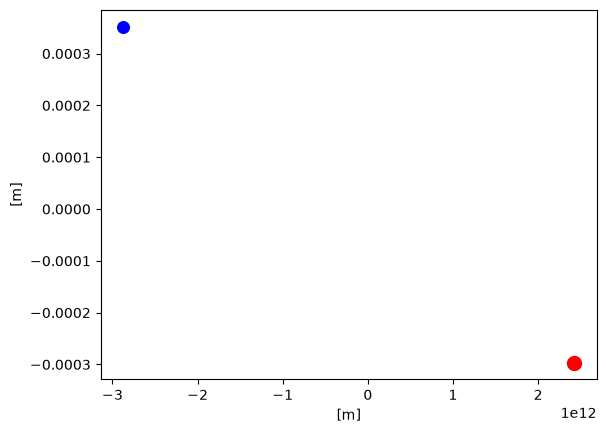

In [33]:
# Plot initial positions 

from amuse.plot import scatter

scatter(alpha_cen_A.x.in_(units.m), alpha_cen_A.y.in_(units.m), s=100, c='red')
scatter(alpha_cen_B.x.in_(units.m), alpha_cen_B.y.in_(units.m), s=70, c='blue')

In [34]:
# Define the converter 

M_scale = M_A + M_B
R_scale = a
converter = nbody_system.nbody_to_si(M_scale, R_scale)

In [42]:
from amuse.community.ph4.interface import Ph4
import numpy as np

# Initialize gravity code
gravity = Ph4(converter)
gravity.particles.add_particles(system)

# Channel for copying results back
channel = gravity.particles.new_channel_to(system) # from gravity code to python 

# Output arrays
times_saved = []

xA, yA, zA = [], [], []
vxA, vyA, vzA = [], [], []

xB, yB, zB = [], [], []
vxB, vyB, vzB = [], [], []

times = np.arange(0, 200.0, 0.1) | units.yr # 200 years

for time in times:
    print(f"Model time = {time} yr")
    gravity.evolve_model(time)
    channel.copy()

    times_saved.append(time.value_in(units.yr))

    xA.append(system[0].x.value_in(units.au))
    yA.append(system[0].y.value_in(units.au))
    zA.append(system[0].z.value_in(units.au))

    vxA.append(system[0].vx.value_in(units.kms))
    vyA.append(system[0].vy.value_in(units.kms))
    vzA.append(system[0].vz.value_in(units.kms))

    xB.append(system[1].x.value_in(units.au))
    yB.append(system[1].y.value_in(units.au))
    zB.append(system[1].z.value_in(units.au))

    vxB.append(system[1].vx.value_in(units.kms))
    vyB.append(system[1].vy.value_in(units.kms))
    vzB.append(system[1].vz.value_in(units.kms))

gravity.stop()

Model time = 0.0 yr yr
Model time = 0.1 yr yr
Model time = 0.2 yr yr
Model time = 0.3 yr yr
Model time = 0.4 yr yr
Model time = 0.5 yr yr
Model time = 0.6 yr yr
Model time = 0.7 yr yr
Model time = 0.8 yr yr
Model time = 0.9 yr yr
Model time = 1.0 yr yr
Model time = 1.1 yr yr
Model time = 1.2 yr yr
Model time = 1.3 yr yr
Model time = 1.4 yr yr
Model time = 1.5 yr yr
Model time = 1.6 yr yr
Model time = 1.7 yr yr
Model time = 1.8 yr yr
Model time = 1.9 yr yr
Model time = 2.0 yr yr
Model time = 2.1 yr yr
Model time = 2.2 yr yr
Model time = 2.3 yr yr
Model time = 2.4 yr yr
Model time = 2.5 yr yr
Model time = 2.6 yr yr
Model time = 2.7 yr yr
Model time = 2.8 yr yr
Model time = 2.9 yr yr
Model time = 3.0 yr yr
Model time = 3.1 yr yr
Model time = 3.2 yr yr
Model time = 3.3 yr yr
Model time = 3.4 yr yr
Model time = 3.5 yr yr
Model time = 3.6 yr yr
Model time = 3.7 yr yr
Model time = 3.8 yr yr
Model time = 3.9 yr yr
Model time = 4.0 yr yr
Model time = 4.1 yr yr
Model time = 4.2 yr yr
Model time 

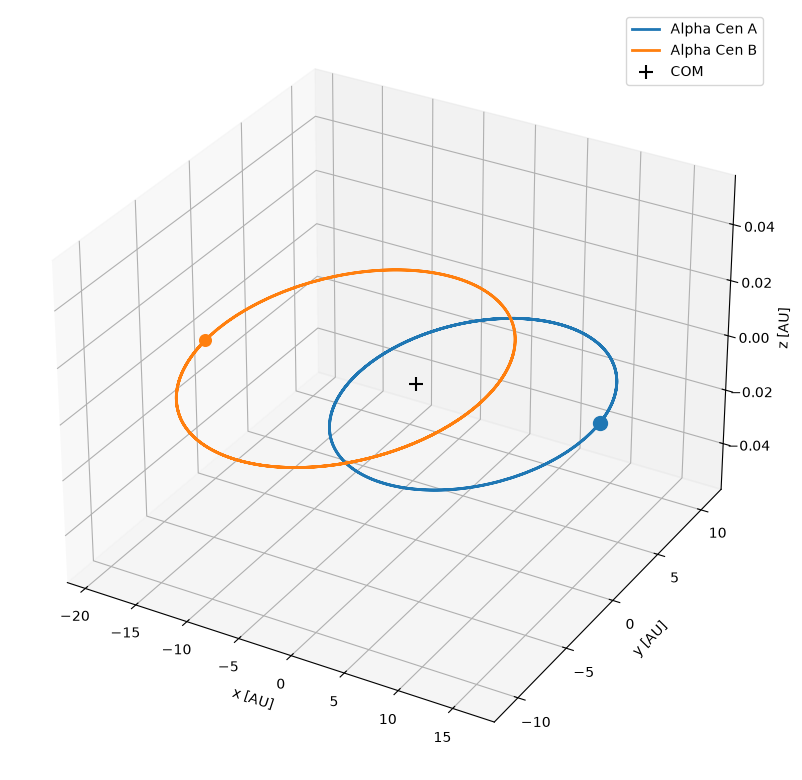

In [43]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(xA, yA, zA, lw=2, label="Alpha Cen A")
ax.plot(xB, yB, zB, lw=2, label="Alpha Cen B")

ax.scatter(xA[0], yA[0], zA[0], s=100, marker="o")
ax.scatter(xB[0], yB[0], zB[0], s=70, marker="o")

ax.scatter(0, 0, 0, color="k", marker="+", s=100, label="COM")

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")

ax.legend()
plt.tight_layout()

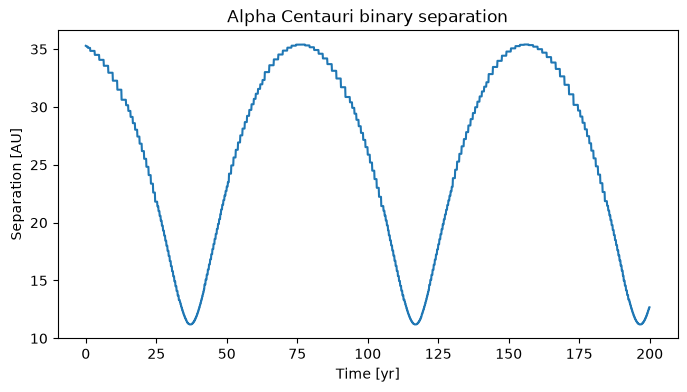

In [44]:
separation = np.sqrt(
    (np.array(xA) - np.array(xB))**2 +
    (np.array(yA) - np.array(yB))**2 +
    (np.array(zA) - np.array(zB))**2
)

plt.figure(figsize=(8, 4))
plt.plot(times_saved, separation)

plt.xlabel("Time [yr]")
plt.ylabel("Separation [AU]")
plt.title("Alpha Centauri binary separation")

plt.show()

In [ ]:
# Animating the orbit 

from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
import matplotlib.pyplot as plt


step = 20
color_A = "tab:blue"
color_B = "tab:orange"

xA_anim = np.array(xA)[::step] # animate every 20th frame 
yA_anim = np.array(yA)[::step]
zA_anim = np.array(zA)[::step]

xB_anim = np.array(xB)[::step]
yB_anim = np.array(yB)[::step]
zB_anim = np.array(zB)[::step]

times_anim = np.array(times_saved)[::step]

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

all_x = np.concatenate([xA_anim, xB_anim])
all_y = np.concatenate([yA_anim, yB_anim])
all_z = np.concatenate([zA_anim, zB_anim])

extent = max(np.max(np.abs(all_x)), np.max(np.abs(all_y)), np.max(np.abs(all_z))) # axes limits

ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.set_zlim(-extent, extent)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")

starA, = ax.plot([], [], [], "o", ms=8, label="Alpha Cen A", color=color_A) # create empty plotting functions for animation
starB, = ax.plot([], [], [], "o", ms=8, label="Alpha Cen B", color=color_B)

trailA, = ax.plot([], [], [], lw=2, color=color_A)
trailB, = ax.plot([], [], [], lw=2, color=color_B)

ax.scatter(0, 0, 0, c="k", marker="+", s=100, label="COM")

ax.legend()

def update(frame): # update function called once every frame

    starA.set_data([xA_anim[frame]], [yA_anim[frame]])
    starA.set_3d_properties([zA_anim[frame]]) # position of A

    starB.set_data([xB_anim[frame]], [yB_anim[frame]]) # position of B
    starB.set_3d_properties([zB_anim[frame]])

    trailA.set_data(xA_anim[:frame+1], yA_anim[:frame+1]) # plot trail as line up to frame+1
    trailA.set_3d_properties(zA_anim[:frame+1])

    trailB.set_data(xB_anim[:frame+1], yB_anim[:frame+1])
    trailB.set_3d_properties(zB_anim[:frame+1])

    ax.set_title(f"t = {times_anim[frame]:.1f} yr") # time as title 

    return starA, starB, trailA, trailB

anim = FuncAnimation(fig, update, frames=len(xA_anim), interval=30, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())